In [2]:
import numpy as np
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date
import statsmodels.api as sm

In [3]:
# Assets for the portfolio

tickers = [
    "AAPL",  # Apple
    "NVDA",  # Nvidia
    "MSFT",  # Microsoft
    "JPM",   # JPMorgan Chase
    "BAC",   # Bank of America
    "SHEL",  # Shell
    "XOM",   # Exxon Mobil
    "GLD",   # SPDR Gold Shares
    "BZ=F",  # Brent crude oil futures
    "NG=F"   # Natural gas (Henry Hub) futures
]


# Time period
START_DATE = "2010-01-01"
END_DATE = date.today().strftime("%Y-%m-%d")

In [4]:
# Getting data from Yahoo Finance

data = yf.download(
    tickers,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=True,
    progress=False
)

In [5]:
data

Price            Close                                                 \
Ticker            AAPL        BAC        BZ=F         GLD         JPM   
Date                                                                    
2010-01-04    6.400960  11.977126   80.120003  109.800003   28.012625   
2010-01-05    6.412026  12.366440   80.589996  109.699997   28.555231   
2010-01-06    6.310037  12.511477   81.889999  111.510002   28.712130   
2010-01-07    6.298369  12.923694   81.510002  110.820000   29.280867   
2010-01-08    6.340243  12.809185   81.370003  111.370003   29.208956   
...                ...        ...         ...         ...         ...   
2026-10-05  332.890015  54.000000  100.320000  379.549988  330.730011   
2026-10-06  333.630005  54.090000  100.580002  382.269989  331.279999   
2026-10-07  336.670013  53.520000  100.199997  375.880005  329.579987   
2026-10-08  340.420013  53.610001  104.279999  378.619995  331.420013   
2026-10-09  336.640015  54.320000  104.720001  384.579987  332.989990   

Price                                                              ...  \
Ticker            MSFT   NG=F        NVDA        SHEL         XOM  ...   
Date                                                               ...   
2010-01-04   22.984232  5.884    0.422817   26.799501   37.136822  ...   
2010-01-05   22.991661  5.637    0.428992   26.829586   37.281807  ...   
2010-01-06   22.850565  6.009    0.431736   26.610374   37.604042  ...   
2010-01-07   22.612928  5.806    0.423275   26.481428   37.485889  ...   
2010-01-08   22.768875  5.749    0.424189   26.442745   37.335518  ...   
...                ...    ...         ...         ...         ...  ...   
2026-10-05  525.179993  3.066  238.899994   96.519997  164.000000  ...   
2026-10-06  529.299988  3.114  239.240005   97.620003  164.479996  ...   
2026-10-07  529.760010  3.203  237.470001   96.849998  164.050003  ...   
2026-10-08  522.609985  3.168  230.479996  100.199997  168.500000  ...   
2026-10-09  535.070007  3.220  229.279999  100.180000  168.940002  ...   

Price            Volume                                                \
Ticker             AAPL          BAC     BZ=F         GLD         JPM   
Date                                                                    
2010-01-04  493729600.0  180845200.0     97.0  16224100.0  35460500.0   
2010-01-05  601904800.0  209521300.0     97.0  14213100.0  41208300.0   
2010-01-06  552160000.0  205257900.0      7.0  24981900.0  27729000.0   
2010-01-07  477131200.0  320868400.0      7.0  13609800.0  44864700.0   
2010-01-08  447610800.0  220104700.0      7.0  15894600.0  33110100.0   
...                 ...          ...      ...         ...         ...   
2026-10-05   34400900.0   34994400.0  39826.0   4289400.0   5346100.0   
2026-10-06   30449000.0   25370300.0  43157.0   7506100.0   6286800.0   
2026-10-07   34147900.0   30913500.0  47830.0   7216600.0   7003000.0   
2026-10-08   35332400.0   59809500.0  47377.0   9706600.0   8060800.0   
2026-10-09   37855000.0   28737700.0  47377.0   7467200.0   5052000.0   

Price                                                                 
Ticker            MSFT      NG=F         NVDA       SHEL         XOM  
Date                                                                  
2010-01-04  38409100.0   78858.0  800204000.0  1643003.0  27809100.0  
2010-01-05  49749600.0   99492.0  728648000.0  1718458.0  30174700.0  
2010-01-06  58182400.0  140611.0  649168000.0  3040554.0  35044700.0  
2010-01-07  50559700.0  135113.0  547792000.0  1033089.0  27192100.0  
2010-01-08  51197400.0  101153.0  478168000.0  1438017.0  24891800.0  
...                ...       ...          ...        ...         ...  
2026-10-05  26604800.0  159487.0  127171500.0  6929672.0  12475500.0  
2026-10-06  21107500.0  157738.0  101701900.0  8159672.0   9285400.0  
2026-10-07  16790200.0  265951.0   81772400.0  4926866.0   9516200.0  
2026-10-08  20228700.0  282250.0  118697400.0  9098990.0  1328810

In [6]:
# We only keep the Close values and we check dates order
data = data["Close"].sort_index()
data.tail()

Ticker,AAPL,BAC,BZ=F,GLD,JPM,MSFT,NG=F,NVDA,SHEL,XOM
Date,,,,,,,,,,
2026-10-05,332.890015,54.000000,100.320000,379.549988,330.730011,525.179993,3.066,238.899994,96.519997,164.000000
2026-10-06,333.630005,54.090000,100.580002,382.269989,331.279999,529.299988,3.114,239.240005,97.620003,164.479996
2026-10-07,336.670013,53.520000,100.199997,375.880005,329.579987,529.760010,3.203,237.470001,96.849998,164.050003
2026-10-08,340.420013,53.610001,104.279999,378.619995,331.420013,522.609985,3.168,230.479996,100.199997,168.500000
2026-10-09,336.640015,54.320000,104.720001,384.579987,332.989990,535.070007,3.220,229.279999,100.180000,168.940002


In [7]:
# Renaming the columns

data.rename(columns={
    
    "SPY": "S&P 500",
    "AAPL": "Apple",
    "NVDA": "Nvidia",
    "MSFT": "Microsoft",
    "JPM": "JPMorgan",
    "BAC": "Bank of America",
    "SHEL": "Shell",
    "XOM": "Exxon Mobil",
    "GLD": "Gold",
    "BZ=F": "Oil",
    "NG=F": "Gas"
    
},inplace = True)

In [8]:
data.head()

Ticker,Apple,Bank of America,Oil,Gold,JPMorgan,Microsoft,Gas,Nvidia,Shell,Exxon Mobil
Date,,,,,,,,,,
2010-01-04,6.400960,11.977126,80.120003,109.800003,28.012625,22.984232,5.884,0.422817,26.799501,37.136822
2010-01-05,6.412026,12.366440,80.589996,109.699997,28.555231,22.991661,5.637,0.428992,26.829586,37.281807
2010-01-06,6.310037,12.511477,81.889999,111.510002,28.712130,22.850565,6.009,0.431736,26.610374,37.604042
2010-01-07,6.298369,12.923694,81.510002,110.820000,29.280867,22.612928,5.806,0.423275,26.481428,37.485889
2010-01-08,6.340243,12.809185,81.370003,111.370003,29.208956,22.768875,5.749,0.424189,26.442745,37.335518


In [9]:
# Removing NaN values

data.dropna(inplace=True)
data.isna().sum()


Ticker
Apple              0
Bank of America    0
Oil                0
Gold               0
JPMorgan           0
Microsoft          0
Gas                0
Nvidia             0
Shell              0
Exxon Mobil        0
dtype: int64

In [10]:
# Changing columns order

column = ["Nvidia", "Apple", "Microsoft", "JPMorgan", "Bank of America", "Exxon Mobil", "Shell", "Gold", "Oil", "Gas" ]
data = data[column]

In [11]:
data

Ticker,Nvidia,Apple,Microsoft,JPMorgan,Bank of America,Exxon Mobil,Shell,Gold,Oil,Gas
Date,,,,,,,,,,
2010-01-04,0.422817,6.400960,22.984232,28.012625,11.977126,37.136822,26.799501,109.800003,80.120003,5.884
2010-01-05,0.428992,6.412026,22.991661,28.555231,12.366440,37.281807,26.829586,109.699997,80.589996,5.637
2010-01-06,0.431736,6.310037,22.850565,28.712130,12.511477,37.604042,26.610374,111.510002,81.889999,6.009
2010-01-07,0.423275,6.298369,22.612928,29.280867,12.923694,37.485889,26.481428,110.820000,81.510002,5.806
2010-01-08,0.424189,6.340243,22.768875,29.208956,12.809185,37.335518,26.442745,111.370003,81.370003,5.749
...,...,...,...,...,...,...,...,...,...,...
2026-10-05,238.899994,332.890015,525.179993,330.730011,54.000000,164.000000,96.519997,379.549988,100.320000,3.066
2026-10-06,239.240005,333.630005,529.299988,331.279999,54.090000,164.479996,97.620003,382.269989,100.580002,3.114
2026-10-07,237.470001,336.670013,529.760010,329.579987,53.520000,164.050003,96.849998,375.880005,100.199997,3.203


In [12]:
# Calculate asset returns

def returns(row):
    return np.log(row/row.shift(1))

df_returns = data.apply(returns)
df_returns.dropna(inplace=True)
df_returns


Ticker,Nvidia,Apple,Microsoft,JPMorgan,Bank of America,Exxon Mobil,Shell,Gold,Oil,Gas
Date,,,,,,,,,,
2010-01-05,0.014497,0.001727,0.000323,0.019185,0.031988,0.003896,0.001122,-0.000911,0.005849,-0.042885
2010-01-06,0.006376,-0.016034,-0.006156,0.005480,0.011660,0.008606,-0.008204,0.016365,0.016002,0.063906
2010-01-07,-0.019792,-0.001851,-0.010454,0.019615,0.032416,-0.003147,-0.004857,-0.006207,-0.004651,-0.034366
2010-01-08,0.002159,0.006626,0.006873,-0.002459,-0.008900,-0.004019,-0.001462,0.004951,-0.001719,-0.009866
2010-01-11,-0.014116,-0.008861,-0.012802,-0.003363,0.008900,0.011157,0.015484,0.013201,-0.004928,-0.052677
...,...,...,...,...,...,...,...,...,...,...
2026-10-05,0.020938,-0.002400,0.014673,0.000000,0.004640,-0.000061,0.003009,-0.001553,-0.019056,0.010162
2026-10-06,0.001422,0.002220,0.007814,0.001662,0.001665,0.002923,0.011332,0.007141,0.002588,0.015534
2026-10-07,-0.007426,0.009071,0.000869,-0.005145,-0.010594,-0.002618,-0.007919,-0.016857,-0.003785,0.028180


In [13]:
# Parameters values
mu = df_returns.mean()
mu

Ticker
Nvidia             0.001505
Apple              0.000947
Microsoft          0.000752
JPMorgan           0.000592
Bank of America    0.000361
Exxon Mobil        0.000362
Shell              0.000315
Gold               0.000300
Oil                0.000064
Gas               -0.000144
dtype: float64

In [14]:
mu = df_returns.mean().values   # daily average return for each asset
mu

array([ 1.50508223e-03,  9.47302457e-04,  7.52471714e-04,  5.91789897e-04,
        3.61437677e-04,  3.62164633e-04,  3.15224788e-04,  2.99663217e-04,
        6.40125719e-05, -1.44120345e-04])

In [15]:
# std
sigma = df_returns.cov()  # daily covariance matrix
sigma

Ticker,Nvidia,Apple,Microsoft,JPMorgan,Bank of America,Exxon Mobil,Shell,Gold,Oil,Gas
Ticker,,,,,,,,,,
Nvidia,0.000810,0.000237,0.000256,0.000181,0.000213,0.000101,0.000129,0.000012,0.000084,0.000043
Apple,0.000237,0.000316,0.000162,0.000120,0.000143,0.000083,0.000093,0.000009,0.000062,0.000015
Microsoft,0.000256,0.000162,0.000271,0.000122,0.000139,0.000075,0.000094,0.000006,0.000059,0.000040
JPMorgan,0.000181,0.000120,0.000122,0.000299,0.000306,0.000142,0.000156,-0.000007,0.000095,0.000019
Bank of America,0.000213,0.000143,0.000139,0.000306,0.000434,0.000163,0.000172,-0.000012,0.000110,0.000021
Exxon Mobil,0.000101,0.000083,0.000075,0.000142,0.000163,0.000251,0.000208,0.000009,0.000194,0.000059
Shell,0.000129,0.000093,0.000094,0.000156,0.000172,0.000208,0.000307,0.000023,0.000212,0.000052
Gold,0.000012,0.000009,0.000006,-0.000007,-0.000012,0.000009,0.000023,0.000113,0.000022,0.000009
Oil,0.000084,0.000062,0.000059,0.000095,0.000110,0.000194,0.000212,0.000022,0.000550,0.000080


In [16]:
sigma = df_returns.cov().values
sigma # array matrix

array([[ 8.09584381e-04,  2.36980354e-04,  2.55970138e-04,
         1.80768085e-04,  2.13329597e-04,  1.00813234e-04,
         1.29471581e-04,  1.15506004e-05,  8.44278965e-05,
         4.33013840e-05],
       [ 2.36980354e-04,  3.16037787e-04,  1.61628482e-04,
         1.19797077e-04,  1.42673625e-04,  8.27276881e-05,
         9.27664209e-05,  9.37529445e-06,  6.21465854e-05,
         1.48061292e-05],
       [ 2.55970138e-04,  1.61628482e-04,  2.70755897e-04,
         1.21803988e-04,  1.38820244e-04,  7.47976024e-05,
         9.36746422e-05,  6.27557911e-06,  5.89566281e-05,
         3.98296872e-05],
       [ 1.80768085e-04,  1.19797077e-04,  1.21803988e-04,
         2.99000301e-04,  3.05618937e-04,  1.41625010e-04,
         1.55870948e-04, -6.73793206e-06,  9.52712433e-05,
         1.87475681e-05],
       [ 2.13329597e-04,  1.42673625e-04,  1.38820244e-04,
         3.05618937e-04,  4.33858388e-04,  1.62816974e-04,
         1.72284230e-04, -1.24547891e-05,  1.10107139e-04,
         2.

In [17]:
MC = 1000 # 100 000 simulations
rng = np.random.default_rng()

simulated_returns = rng.multivariate_normal(mean=mu,cov=sigma,size=MC)  # matrix MC rows and N = number of assets columns
# for each asset, we have 100,000 return scenarios
simulated_returns

array([[-0.03212331, -0.01846802, -0.01419159, ...,  0.01776044,
        -0.02001877, -0.03506444],
       [ 0.00530657, -0.00544866,  0.03067151, ..., -0.01041977,
        -0.00942123, -0.01349992],
       [ 0.00543472, -0.01529474, -0.00411135, ...,  0.01222429,
        -0.0590517 ,  0.01936234],
       ...,
       [ 0.03810814,  0.00036926,  0.01099055, ...,  0.00745424,
        -0.01318621,  0.01605531],
       [-0.03839432, -0.0391681 , -0.04610618, ...,  0.00579828,
         0.00347643, -0.09735441],
       [ 0.00905911, -0.02028215, -0.01606486, ..., -0.00573366,
         0.009171  , -0.0304477 ]], shape=(1000, 10))

In [18]:
# Spot values of the asset

data.iloc[-1]
spot = data.iloc[-1].values
spot 

array([229.27999878, 336.64001465, 535.07000732, 332.98999023,
        54.31999969, 168.94000244, 100.18000031, 384.57998657,
       104.72000122,   3.22000003])

In [19]:
# Potfolio weight

weight_Nvidia = 0.15
weight_Apple = 0.15
weight_Microsoft = 0.15
weight_JPMorgan = 0.10
weight_Bank_of_America = 0.10
weight_Exxon_Mobil = 0.05
weight_Shell = 0.05
weight_Gold = 0.1
weight_Oil = 0.1 
weight_Gas = 0.05

s = weight_Nvidia + weight_Apple + weight_Microsoft + weight_JPMorgan + weight_Bank_of_America  + weight_Exxon_Mobil + weight_Shell + weight_Gold + weight_Oil + weight_Gas 
print(s)

allocation = [weight_Nvidia, weight_Apple,weight_Microsoft, weight_JPMorgan, weight_Bank_of_America,weight_Exxon_Mobil,weight_Shell, weight_Gold, weight_Oil,weight_Gas ]
allocation = np.array(allocation)
allocation
sum(allocation)

1.0


np.float64(1.0)

In [20]:
# Initial Value of Portfolio
money = 1_000_000
portfolio_allocation = allocation * spot
initial_portfolio_value = np.sum(portfolio_allocation)

In [21]:
# Prix futur simulés
simulated_price = spot * np.exp(simulated_returns)
simulated_price

array([[222.03180859, 330.47999827, 527.53014095, ..., 391.47131114,
        102.6444799 ,   3.1090491 ],
       [230.49992358, 334.8107667 , 551.7356876 , ..., 380.59355738,
        103.73804339,   3.17682238],
       [230.52946301, 331.53036656, 532.87466536, ..., 389.31005555,
         98.71515055,   3.28295427],
       ...,
       [238.18605104, 336.76434502, 540.98315462, ..., 387.45744949,
        103.34820593,   3.27211536],
       [220.64379991, 323.70935121, 510.96005384, ..., 386.81636684,
        105.08468619,   2.92129484],
       [231.36650736, 329.88100684, 526.54285944, ..., 382.38124384,
        105.68480598,   3.12343596]], shape=(1000, 10))

In [25]:
# valeur des nouveaux portefeuilles
portfolio_values = simulated_price @ allocation 
portfolio_values

PnL = portfolio_values - initial_portfolio_value
PnL

array([-3.39510815,  1.92347055, -1.76857443,  2.59888943,  2.57275563,
        2.78597038,  5.75463424,  4.10276106, -1.41524075,  1.74009028,
       -3.45216209,  1.81693156,  0.21832286,  4.53566376, -0.85643777,
        4.96744198,  1.42385748,  4.43791867,  1.46597839, -2.6201135 ,
       -3.03338231,  2.60666586, -3.44796767, -2.4435345 ,  1.72479759,
       -1.41245748,  1.55295174,  2.05281449, -0.61158478, -2.32527358,
        0.23351485, -1.72231138,  2.47557657, -1.76455804,  0.72185414,
        2.29112534, -1.4550818 ,  1.77824709,  2.1469637 , -4.96875828,
        3.18979254,  3.07602922,  0.17034238, -1.59812723,  4.02952699,
       -4.55768064,  3.44318682,  2.66650958,  6.09182832, -1.49888659,
       -1.68717021,  2.23826132, -3.76563383,  1.47733949,  0.20514709,
        0.60584908, -7.82844473, -0.30284266,  2.06625502,  2.4870582 ,
        3.15949214,  7.10202076,  1.13677744,  0.81700488,  0.49168731,
        0.79331714, -0.28264251, -0.83766738, -1.77570265, -1.52

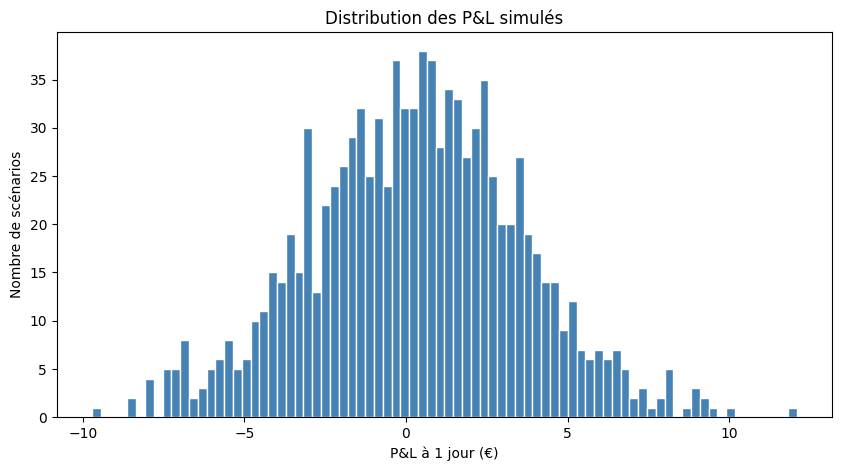

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(PnL, bins=80, color="steelblue", edgecolor="white")

plt.xlabel("P&L à 1 jour (€)")
plt.ylabel("Nombre de scénarios")
plt.title("Distribution des P&L simulés")

plt.show()

In [29]:
var_95 = np.quantile(PnL, 0.05)
var_95

np.float64(-5.222883125246147)